# Healthcare Analytics for Doctor Visits

**Goal:** Understand which factors are associated with how often people visit a doctor.

**Notebook roadmap**
1. Data loading and quality checks
2. Data dictionary and preparation
3. Exploratory analysis (EDA): target variable, group comparisons, correlations
4. Checking for confounding (do variables overlap?)
5. Statistical tests
6. Modelling count data (Poisson vs Negative Binomial)
7. Key findings, limitations and recommendations

> **Requirements:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `statsmodels`
> (install with `pip install statsmodels` if missing). Keep the CSV file in the same folder as this notebook.

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Load the data

In [ ]:
from pathlib import Path

DATA_PATH = Path("1776250375-P2-Healthcare Analytics for Doctor Visits.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. "
        "Keep the CSV file in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", df_raw.shape)
df_raw.head()

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


## 2. Data dictionary

This dataset matches the well-known **DoctorVisits** data (Australian Health Survey, 1977-78). Definitions below follow the original documentation.

| Column | Meaning | Type |
|---|---|---|
| `visits` | Number of doctor visits in the **past 2 weeks** (target) | Count |
| `gender` | male / female | Categorical |
| `age` | Age in years **divided by 100** (0.19 = 19 years) | Numeric |
| `income` | Annual income in **tens of thousands of dollars** | Numeric |
| `illness` | Number of illnesses in the past 2 weeks (0-5) | Count |
| `reduced` | Days of reduced activity in the past 2 weeks due to illness/injury | Count |
| `health` | General Health Questionnaire score; **higher = worse health** | Numeric |
| `private` | Has private health insurance (yes/no) | Binary |
| `freepoor` | Free government cover because of **low income** (yes/no) | Binary |
| `freerepat` | Free government cover due to **old age, disability or veteran (repatriation) status** (yes/no) | Binary |
| `nchronic` | Chronic condition that does **not limit** activity (yes/no) | Binary |
| `lchronic` | Chronic condition that **limits** activity (yes/no) | Binary |
| `Unnamed: 0` | Row identifier (not a measurement) | ID |

## 3. Data quality checks and preparation

In [7]:
print("Missing values per column:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("Duplicate rows ignoring the ID column:", df_raw.drop(columns="Unnamed: 0").duplicated().sum())

Missing values per column:
Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

Duplicate rows: 0
Duplicate rows ignoring the ID column: 1320


There are no missing values. Some rows are identical once the ID column is ignored. This is expected in survey data where many people share the same answers, so we keep them.

In [8]:
df = df_raw.drop(columns="Unnamed: 0").copy()

# Convert yes/no columns to 1/0
binary_cols = ["private", "freepoor", "freerepat", "nchronic", "lchronic"]
for c in binary_cols:
    df[c] = df[c].map({"yes": 1, "no": 0})
df["male"] = (df["gender"] == "male").astype(int)

# More readable versions of age (years) and a per-10-years version for modelling
df["age_years"] = df["age"] * 100
df["age_10"] = df["age_years"] / 10

# Groups used for plots
df["age_group"] = pd.cut(df["age_years"], bins=[0, 24, 39, 59, 100],
                         labels=["19-24", "25-39", "40-59", "60+"])
df["income_quartile"] = pd.qcut(df["income"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
                                duplicates="drop")

print("Age range (years):", df["age_years"].min(), "to", df["age_years"].max())
df.head()

Age range (years): 19.0 to 72.0


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,male,age_years,age_10,age_group,income_quartile
0,1,female,0.190,0.550,1,4,1,1,0,0,0,0,0,19.000,1.900,19-24,Q2
1,1,female,0.190,0.450,1,2,1,1,0,0,0,0,0,19.000,1.900,19-24,Q2
2,1,male,0.190,0.900,3,0,0,0,0,0,0,0,1,19.000,1.900,19-24,Q3
3,1,male,0.190,0.150,1,0,0,0,0,0,0,0,1,19.000,1.900,19-24,Q1 (lowest)
4,1,male,0.190,0.450,2,5,1,0,0,0,1,0,1,19.000,1.900,19-24,Q2


## 4. Exploratory data analysis

### 4.1 Summary statistics

In [9]:
num_cols = ["visits", "age_years", "income", "illness", "reduced", "health"]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
visits,"5,190.000",0.302,0.798,0.000,0.000,0.000,0.000,9.000
age_years,"5,190.000",40.639,20.478,19.000,22.000,32.000,62.000,72.000
income,"5,190.000",0.583,0.369,0.000,0.250,0.550,0.900,1.500
illness,"5,190.000",1.432,1.384,0.000,0.000,1.000,2.000,5.000
reduced,"5,190.000",0.862,2.888,0.000,0.000,0.000,0.000,14.000
health,"5,190.000",1.218,2.124,0.000,0.000,0.000,2.000,12.000


### 4.2 The target variable: `visits`

Share of people with 0 visits : 79.8%
Mean visits                   : 0.302
Variance of visits            : 0.637
Variance / mean ratio         : 2.11  (a Poisson distribution would give about 1)


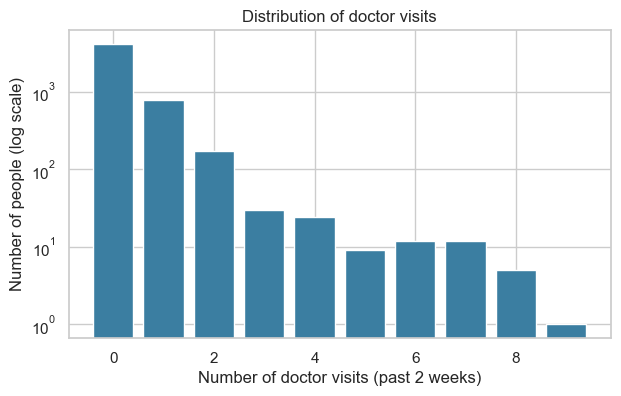

In [10]:
zero_share = (df["visits"] == 0).mean()
mean_v, var_v = df["visits"].mean(), df["visits"].var()
print(f"Share of people with 0 visits : {zero_share:.1%}")
print(f"Mean visits                   : {mean_v:.3f}")
print(f"Variance of visits            : {var_v:.3f}")
print(f"Variance / mean ratio         : {var_v/mean_v:.2f}  (a Poisson distribution would give about 1)")

fig, ax = plt.subplots(figsize=(7, 4))
counts = df["visits"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#3b7ea1")
ax.set_yscale("log")
ax.set_xlabel("Number of doctor visits (past 2 weeks)")
ax.set_ylabel("Number of people (log scale)")
ax.set_title("Distribution of doctor visits")
plt.show()

**Observation:** Most people had no visits, and the distribution has a long right tail. The variance is larger than the mean (*overdispersion*), so a plain Poisson model may be too restrictive. We test this in the modelling section.

### 4.3 Average visits by yes/no and gender groups

In [11]:
group_vars = {
    "gender": "Gender",
    "private": "Private insurance",
    "freepoor": "Free cover (low income)",
    "freerepat": "Free cover (age/disability/veteran)",
    "nchronic": "Chronic, not limiting",
    "lchronic": "Chronic, limiting",
}

rows = []
for col, label in group_vars.items():
    g = df.groupby(col)["visits"].agg(["mean", "count"])
    for level, r in g.iterrows():
        rows.append({"Factor": label, "Group": level, "Avg visits": r["mean"], "People": int(r["count"])})
group_table = pd.DataFrame(rows)
group_table

,Factor,Group,Avg visits,People
0,Gender,female,0.362,2702
1,Gender,male,0.236,2488
2,Private insurance,0,0.307,2892
3,Private insurance,1,0.295,2298
4,Free cover (low income),0,0.308,4968
5,Free cover (low income),1,0.158,222
6,Free cover (age/disability/veteran),0,0.258,4099
7,Free cover (age/disability/veteran),1,0.467,1091
8,"Chronic, not limiting",0,0.272,3098
9,"Chronic, not limiting",1,0.346,2092


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, (col, label) in zip(axes.ravel(), group_vars.items()):
    sns.barplot(data=df, x=col, y="visits", errorbar=("ci", 95), ax=ax, color="#3b7ea1")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("Avg visits")
fig.suptitle("Average doctor visits by group (95% confidence intervals)", y=1.02)
plt.tight_layout()
plt.show()

### 4.4 Visits by illness, age and income

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

sns.barplot(data=df, x="illness", y="visits", errorbar=("ci", 95), ax=axes[0], color="#3b7ea1")
axes[0].set_title("By number of illnesses")

sns.barplot(data=df, x="age_group", y="visits", errorbar=("ci", 95), ax=axes[1], color="#3b7ea1")
axes[1].set_title("By age group")
axes[1].set_xlabel("Age group (years)")

sns.barplot(data=df, x="income_quartile", y="visits", errorbar=("ci", 95), ax=axes[2], color="#3b7ea1")
axes[2].set_title("By income quartile")
axes[2].set_xlabel("")

for ax in axes:
    ax.set_ylabel("Avg visits")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
sns.barplot(data=df, x=pd.cut(df["reduced"], [-1, 0, 3, 7, 14], labels=["0", "1-3", "4-7", "8-14"]),
            y="visits", errorbar=("ci", 95), ax=axes[0], color="#3b7ea1")
axes[0].set_title("By days of reduced activity")
axes[0].set_xlabel("Days reduced (past 2 weeks)")

sns.barplot(data=df, x=pd.cut(df["health"], [-1, 0, 2, 5, 12], labels=["0 (best)", "1-2", "3-5", "6-12 (worst)"]),
            y="visits", errorbar=("ci", 95), ax=axes[1], color="#3b7ea1")
axes[1].set_title("By health score (higher = worse)")
axes[1].set_xlabel("Health score band")
for ax in axes:
    ax.set_ylabel("Avg visits")
plt.tight_layout()
plt.show()

### 4.5 Correlations

In [ ]:
corr_cols = ["visits", "age_years", "income", "illness", "reduced", "health",
             "male", "private", "freepoor", "freerepat", "nchronic", "lchronic"]
corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation matrix")
plt.show()

corr["visits"].drop("visits").sort_values(ascending=False).to_frame("Spearman r with visits")

## 5. Checking for confounding

Raw group averages can mislead when groups differ in other ways. For example, older people may have lower incomes, so the "income effect" may partly be an "age effect". We check the main suspects.

In [ ]:
print("Spearman correlation between age and income: %.3f" % stats.spearmanr(df["age_years"], df["income"])[0])

summary = df.groupby("freepoor")[["age_years", "income", "illness", "reduced", "health", "lchronic", "visits"]].mean()
summary.index = ["Not on low-income free cover", "On low-income free cover"]
print("\nFree cover for low income: how do the two groups differ?")
display(summary)

summary2 = df.groupby("freerepat")[["age_years", "income", "illness", "reduced", "health", "lchronic", "visits"]].mean()
summary2.index = ["Not on age/disability/veteran cover", "On age/disability/veteran cover"]
print("\nFree cover for age/disability/veteran status: how do the two groups differ?")
display(summary2)

**What this shows:** Age and income are negatively related (older people tend to have lower incomes), so the raw "age effect" and "income effect" overlap. People on age/disability/veteran cover (`freerepat`) are much older and report more illness. People on low-income cover (`freepoor`) are much younger, which helps explain their low raw visit average. This is why a regression that controls for several variables at once is needed (Section 7), rather than reading raw averages as causes.

## 6. Statistical tests

Because `visits` is a skewed count, we use non-parametric tests (Mann-Whitney U for two groups, Spearman for association).

In [ ]:
rows = []
for col, label in group_vars.items():
    key = "male" if col == "gender" else col
    a = df.loc[df[key] == 1, "visits"]
    b = df.loc[df[key] == 0, "visits"]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"Factor": label, "Mean (group=1)": a.mean(), "Mean (group=0)": b.mean(), "p-value": p})
tests = pd.DataFrame(rows)
tests["Significant at 5%?"] = np.where(tests["p-value"] < 0.05, "Yes", "No")
tests["p-value"] = tests["p-value"].map(lambda p: f"{p:.2e}")
print("Mann-Whitney U tests (group=1 means: male / yes)")
tests

In [ ]:
rows = []
for col in ["age_years", "income", "illness", "reduced", "health"]:
    r, p = stats.spearmanr(df[col], df["visits"])
    rows.append({"Variable": col, "Spearman r": r, "p-value": f"{p:.2e}"})
pd.DataFrame(rows)

## 7. Modelling doctor visits

`visits` is a count, so we use count models:

- **Poisson regression**: assumes variance = mean.
- **Negative Binomial regression**: allows variance > mean (overdispersion).

We report results as **incidence rate ratios (IRR)**: IRR = 1.20 means about 20% more visits, all other variables held constant; IRR = 0.80 means about 20% fewer. Age is expressed per **10 years** and income per **\$10,000**.

In [ ]:
formula = ("visits ~ male + age_10 + income + illness + reduced + health "
           "+ private + freepoor + freerepat + nchronic + lchronic")

poisson = smf.glm(formula, data=df, family=sm.families.Poisson()).fit()

dispersion = poisson.pearson_chi2 / poisson.df_resid
print(f"Poisson dispersion (Pearson chi2 / df): {dispersion:.2f}  (about 1 is ideal; clearly above 1 means overdispersion)")
poisson.summary()

In [ ]:
negbin = smf.negativebinomial(formula, data=df).fit(disp=0, maxiter=200)
negbin.summary()

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Poisson", "Negative Binomial"],
    "Log-likelihood": [poisson.llf, negbin.llf],
    "AIC": [poisson.aic, negbin.aic],
})
comparison["Better (lower AIC)"] = np.where(comparison["AIC"] == comparison["AIC"].min(), "<-- best", "")
comparison

A lower AIC means a better balance of fit and simplicity. We interpret the better-fitting model below.

In [ ]:
best = negbin if negbin.aic < poisson.aic else poisson
best_name = "Negative Binomial" if best is negbin else "Poisson"

params = best.params.drop("alpha", errors="ignore")
ci = best.conf_int().drop("alpha", errors="ignore")
pvals = best.pvalues.drop("alpha", errors="ignore")

irr = pd.DataFrame({
    "IRR": np.exp(params),
    "CI lower (95%)": np.exp(ci[0]),
    "CI upper (95%)": np.exp(ci[1]),
    "p-value": pvals,
}).drop(index="Intercept")
irr["Significant (5%)"] = np.where(irr["p-value"] < 0.05, "Yes", "No")
irr = irr.sort_values("IRR", ascending=False)

print(f"Incidence rate ratios from the {best_name} model")
irr

In [ ]:
plot_df = irr.sort_values("IRR")
fig, ax = plt.subplots(figsize=(8, 6))
colors = np.where(plot_df["Significant (5%)"] == "Yes", "#1b6ca8", "#b0b0b0")
ax.hlines(plot_df.index, plot_df["CI lower (95%)"], plot_df["CI upper (95%)"], color=colors, lw=2)
ax.scatter(plot_df["IRR"], plot_df.index, color=colors, zorder=3)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Incidence rate ratio (log scale; 1 = no effect)")
ax.set_title(f"Effect on doctor visits ({best_name} model)\nblue = significant at 5%, grey = not significant")
plt.tight_layout()
plt.show()

### Model check: how well do the models reproduce the many zeros?

In [ ]:
observed_zeros = (df["visits"] == 0).sum()

# Poisson: expected zeros = sum of exp(-mu)
mu_pois = poisson.predict(df)
exp_zeros_pois = np.exp(-mu_pois).sum()

# Negative binomial: P(0) = (1 + alpha*mu)^(-1/alpha)
alpha = negbin.params["alpha"]
mu_nb = negbin.predict(df)
exp_zeros_nb = ((1 + alpha * mu_nb) ** (-1 / alpha)).sum()

pd.DataFrame({
    "Observed zeros": [observed_zeros],
    "Expected (Poisson)": [exp_zeros_pois],
    "Expected (Negative Binomial)": [exp_zeros_nb],
}).round(0).astype(int)

If the Negative Binomial model's expected zeros are close to the observed number, a zero-inflated model is not strongly needed.

## 8. Key findings

*(Run the whole notebook first; the tables and charts above are what these points refer to.)*

1. **Most people did not see a doctor.** About 80% had zero visits in the 2-week window, and the variance is about twice the mean, so the data is overdispersed. Compare the AIC values in Section 7 to confirm which model fits better.
2. **Immediate health need is the strongest driver.** After controlling for the other variables, the number of illnesses, days of reduced activity and the health score are the clearest predictors: each extra illness is associated with roughly 20% more visits, and each extra reduced-activity day with roughly 13% more.
3. **Gender:** women visit more often than men, even after controlling for health and other factors (the `male` IRR is below 1).
4. **Chronic conditions, age, income and insurance:** these look important in raw averages (for example, people with activity-limiting chronic conditions average about 0.60 visits vs 0.26), but their effects shrink and become statistically weak once illness, reduced activity and the health score are in the model. Much of their raw association is likely shared with those health-need measures. Check the p-values and confidence intervals in the IRR table before making strong claims.
5. **Free low-income cover (`freepoor`)** looks lower in raw averages, but that group is small (222 people), younger, and differs in other ways, so interpret it cautiously.

## 9. Limitations

- **Association, not causation.** This is observational survey data.
- **Short window.** Visits are counted over only 2 weeks, so many people have zero by chance.
- **Old data (Australia, 1977-78).** Healthcare systems and costs have changed.
- **Self-reported variables** (illnesses, reduced days, health score) can contain reporting bias.
- **Overlapping predictors.** Illness, reduced days, health score and chronic conditions are related to each other, which can make individual coefficients less stable.
- Some groups are small (for example, `freepoor` has only 222 people), which makes estimates less stable.

## 10. Recommendations / next steps

- Focus on current health need (frequent illness, days of reduced activity) when identifying people likely to need more doctor visits; chronic condition status adds less once these are known.
- Try a **zero-inflated** or **hurdle** model if the zero check in Section 7 shows a clear gap between observed and expected zeros.
- Add interaction terms (for example, age x gender) or test non-linear age effects.
- Validate with a train/test split or cross-validation if the goal is prediction.